**Notebook 12: H3 Operational Simulation Demonstration**


H3 Operational Simulation and Response Validation

H3: Cybersecurity analytics reduces the operational impact of simulated denial of service conditions in RFID baggage tracking environments.

RQ3: How effective are cybersecurity analytics in reducing denial of service risks in baggage tracking?

The operational simulation examines how RFID baggage tracking records are processed when network communication is disrupted. The analysis uses 75 affected RFID scans across 10 simulated DoS disruptions. Four operating conditions are evaluated: no buffering, buffering only, traditional rule response, and machine learning response.

The RFID records come from the prepared baggage tracking dataset. The cybersecurity detection decisions come from the CICIDS2017 analysis in Notebook 10. These two sources are connected through a controlled simulation rather than an operating airport network.

The simulation measures delivered scans, lost scans, delivery delays, and buffering activity. Network capacity, response timing, and protective effectiveness are experimental assumptions. The results describe the behavior of the simulated system and are not measurements of actual airport operations.

Step 1: Connect and Review the Prepared RFID Data

The prepared RFID baggage tracking file and saved H3 cybersecurity detection results are connected to the research environment. The data are reviewed to confirm the number of RFID records, affected scans, and DoS disruptions.

The analysis also verifies that each affected scan has a unique identifier and that each disruption has one corresponding detection result.

The earlier Codespaces analysis identified 31,575 RFID records, 75 affected scans, 10 disruptions, zero traditional rule alerts, and eight machine learning alerts. These values are checked again using the source files.

In [1]:
# Step 1: Connect and review the prepared RFID data

# Load the libraries

from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

# Find the main research project folder

current_folder = Path.cwd()

main_folder = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / "06_Prepared_Data/02_Prepared_RFID_Data.csv").exists()
    ),
    None
)

# Confirm the project folder was found

if main_folder is None:
    raise FileNotFoundError(
        "Open the notebook inside the research project."
    )

# Identify the source files

rfid_file = main_folder / (
    "06_Prepared_Data/02_Prepared_RFID_Data.csv"
)

alerts_file = main_folder / (
    "09_H3_Results/h3_adaptive_detection_decisions.csv"
)

results_folder = main_folder / "09_H3_Results"

# Confirm the detection results are available

if not alerts_file.exists():
    raise FileNotFoundError(
        "The Notebook 10 detection results were not found."
    )

# Load the existing data

rfid_data = pd.read_csv(rfid_file)

alerts = pd.read_csv(alerts_file)

# Select the RFID scans affected by DoS disruptions

dos_scans = rfid_data.loc[
    rfid_data["disruption_window"] == 1
].copy()

# Convert timestamps to date and time values

dos_scans["timestamp"] = pd.to_datetime(
    dos_scans["timestamp"],
    errors="coerce"
)

# Validate the source records

assert dos_scans["timestamp"].notna().all(), \
    "Invalid timestamps found."

assert dos_scans["scan_id"].is_unique, \
    "Duplicate scan identifiers found."

assert alerts["disruption_id"].is_unique, \
    "Duplicate detection records found."

assert set(alerts["disruption_id"]) == set(
    dos_scans["disruption_id"]
), "Disruption identifiers do not match."

# Check for missing or invalid detection decisions

assert alerts[["rule_alert", "ml_alert"]].notna().all().all()

assert alerts["rule_alert"].isin([0, 1]).all()

assert alerts["ml_alert"].isin([0, 1]).all()

# Display the results

print("Prepared RFID records:", len(rfid_data))

print("DoS affected scans:", len(dos_scans))

print(
    "Disruption groups:",
    dos_scans["disruption_id"].nunique()
)

print(
    "Traditional rule alerts:",
    int(alerts["rule_alert"].sum())
)

print(
    "Machine learning alerts:",
    int(alerts["ml_alert"].sum())
)

print("\nStep 1 complete.")

Prepared RFID records: 31575
DoS affected scans: 75
Disruption groups: 10
Traditional rule alerts: 0
Machine learning alerts: 8

Step 1 complete.


Step 2: Review the DoS Disruptions and Operating Conditions

The 75 affected RFID scans are reviewed to identify the number of disruptions, affected baggage journeys, and assigned outage durations.

Four operating conditions are defined for comparison. The first condition represents no buffering. The second uses temporary storage without an active cybersecurity response. The third applies a response when a traditional rule alert occurs. The fourth applies the same response when a machine learning alert occurs.

The starting simulation uses a buffer capacity of six scans, a recovery capacity of two scans per minute, and a protective processing capacity of one scan per minute. Protection is assumed to begin five minutes after the disruption starts when an alert is present.

These values are controlled research assumptions and do not represent actual airport system specifications.

In [2]:
# Step 2: Review the DoS disruptions and operating conditions

# Summarize affected scans and baggage journeys

disruption_summary = dos_scans.groupby(
    "disruption_id"
).agg(
    affected_scans=("scan_id", "count"),
    affected_journeys=("bag_id", "nunique"),
    disruption_minutes=("disruption_minutes", "first")
).reset_index()

# Connect the detection decisions

disruption_summary = disruption_summary.merge(
    alerts,
    on="disruption_id",
    how="left",
    validate="one_to_one"
)

# Define the four operating conditions

scenario_names = [
    "No buffering",
    "Buffering only",
    "Rule response",
    "ML response"
]

# Set the experimental operating conditions

buffer_capacity = 6

recovery_capacity = 2

response_start_minute = 5

protected_capacity = 1

# Prepare the results folder

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Display the disruption summary

print("DoS disruption summary:")

display(disruption_summary)

print("\nOperating conditions:")

for scenario in scenario_names:
    print(scenario)

print("\nBuffer capacity:", buffer_capacity)

print("Recovery capacity:", recovery_capacity)

print("Response activation minute:", response_start_minute)

print("Protected capacity:", protected_capacity)

print("\nStep 2 complete.")

DoS disruption summary:


,disruption_id,affected_scans,affected_journeys,disruption_minutes,rule_alert,ml_alert
0,DOS01,8,8,20,0,1
1,DOS02,8,8,16,0,1
2,DOS03,8,8,27,0,1
3,DOS04,8,8,29,0,1
4,DOS05,8,8,20,0,0
5,DOS06,7,7,17,0,1
6,DOS07,7,7,21,0,1
7,DOS08,7,7,17,0,1
8,DOS09,7,7,23,0,0
9,DOS10,7,7,17,0,1



Operating conditions:
No buffering
Buffering only
Rule response
ML response

Buffer capacity: 6
Recovery capacity: 2
Response activation minute: 5
Protected capacity: 1

Step 2 complete.


Step 3: Prepare the Simulated Scan Arrival Times

The original RFID timestamps are reviewed to establish the order in which affected scans occurred. The earlier analysis found that scan records grouped under individual disruptions spanned 46 to 86 minutes, while the assigned disruption durations ranged from 16 to 29 minutes.

A separate scenario arrival time is calculated for each affected scan. This places the records within their assigned simulated outage windows while preserving their order and approximate relative spacing.

The original timestamps remain unchanged. The adjusted arrival times represent a controlled simulation assumption rather than actual observed network arrival times.

In [3]:
# Step 3: Prepare the simulated scan arrival times

# Sort scans by disruption and original timestamp

dos_scans = dos_scans.sort_values(
    ["disruption_id", "timestamp", "scan_id"]
).copy()

# Find the first scan in each disruption

first_scan_time = dos_scans.groupby(
    "disruption_id"
)["timestamp"].transform("min")

# Calculate the original elapsed arrival minutes

dos_scans["arrival_minute"] = (
    (
        dos_scans["timestamp"] - first_scan_time
    ).dt.total_seconds() / 60
).round().astype(int)

# Find the last arrival minute in each disruption

last_scan_minute = dos_scans.groupby(
    "disruption_id"
)["arrival_minute"].transform("max")

# Check that the disruption times are valid

assert (last_scan_minute > 0).all()

assert (dos_scans["disruption_minutes"] > 0).all()

# Create separate simulated arrival times

dos_scans["scenario_arrival_minute"] = (
    dos_scans["arrival_minute"]
    / last_scan_minute
    * (dos_scans["disruption_minutes"] - 1)
).round().astype(int)

# Connect the saved cybersecurity alerts

connected_scans = dos_scans.merge(
    alerts,
    on="disruption_id",
    how="left",
    validate="many_to_one"
)

# Verify the modeled arrivals fit within the outages

valid_arrivals = (
    connected_scans["scenario_arrival_minute"]
    < connected_scans["disruption_minutes"]
).all()

assert valid_arrivals, \
    "Some simulated arrivals are outside the outage window."

# Summarize the original and modeled arrival times

arrival_summary = connected_scans.groupby(
    "disruption_id"
).agg(
    affected_scans=("scan_id", "count"),
    original_last_minute=("arrival_minute", "max"),
    modeled_last_minute=("scenario_arrival_minute", "max"),
    outage_minutes=("disruption_minutes", "first")
).reset_index()

# Display the results

print("Original and simulated scan arrival times:")

display(arrival_summary)

print(
    "\nAll arrivals within disruption windows:",
    valid_arrivals
)

print("\nStep 3 complete.")

Original and simulated scan arrival times:


,disruption_id,affected_scans,original_last_minute,modeled_last_minute,outage_minutes
0,DOS01,8,85,19,20
1,DOS02,8,86,15,16
2,DOS03,8,46,26,27
3,DOS04,8,78,28,29
4,DOS05,8,68,19,20
5,DOS06,7,69,16,17
6,DOS07,7,77,20,21
7,DOS08,7,77,16,17
8,DOS09,7,63,22,23
9,DOS10,7,49,16,17



All arrivals within disruption windows: True

Step 3 complete.


Step 4: Create the Operational Buffer and Recovery Simulation

The operational simulation processes the affected RFID scans one minute at a time. Each scan enters the simulated system according to its assigned scenario arrival time.

When network communication is unavailable, scans are temporarily stored in the buffer. If the buffer reaches its capacity, additional scans are recorded as lost. Once communication is restored, the system begins delivering the waiting scans.

When a cybersecurity alert activates the modeled protective response, limited processing capacity becomes available during the disruption. This allows the simulation to measure whether the protective action changes scan delivery, delay, and loss.

The program records the outcome of each scan and the network activity during each simulated minute. These results provide observable evidence of how the system behaves under the selected experimental conditions.

In [4]:
# Step 4: Create the operational buffer and recovery simulation

# Create a function to process the RFID scans

def simulate_scans(
    records,
    scenario,
    buffer_size=6,
    recovery_rate=2,
    response_start=5,
    response_rate=1
):

    # Create lists to store the results

    scan_results = []
    buffer_history = []

    # Process each disruption separately

    for disruption_id, group in records.groupby("disruption_id"):

        # Identify the outage duration and detection decisions

        outage_minutes = int(
            group["disruption_minutes"].iloc[0]
        )

        traditional_alert = int(
            group["rule_alert"].iloc[0]
        )

        ml_alert = int(
            group["ml_alert"].iloc[0]
        )

        # Create an empty buffer for waiting scans

        waiting_scans = []

        # Allow additional time to deliver buffered scans

        last_minute = (
            outage_minutes
            + len(group)
            + buffer_size
            + 5
        )

        # Process the network one minute at a time

        for minute in range(last_minute + 1):

            # Identify new scans arriving during this minute

            arriving = group.loc[
                group["scenario_arrival_minute"] == minute
            ]

            lost_this_minute = 0
            delivered_this_minute = 0

            # Process each newly arriving scan

            for _, scan in arriving.iterrows():

                scan_id = scan["scan_id"]
                bag_id = scan["bag_id"]

                # Without buffering, the affected scan is lost

                if scenario == "No buffering":

                    scan_results.append((
                        scenario,
                        disruption_id,
                        scan_id,
                        bag_id,
                        "Lost",
                        None,
                        None
                    ))

                    lost_this_minute += 1

                # Store the scan if buffer space is available

                elif len(waiting_scans) < buffer_size:

                    waiting_scans.append((
                        scan_id,
                        bag_id,
                        minute
                    ))

                # Record the scan as lost if the buffer is full

                else:

                    scan_results.append((
                        scenario,
                        disruption_id,
                        scan_id,
                        bag_id,
                        "Lost",
                        None,
                        None
                    ))

                    lost_this_minute += 1

            # Network communication returns after the outage

            if minute >= outage_minutes:

                capacity = recovery_rate

            else:

                capacity = 0

            # Track whether protective processing is active

            alert_active = False

            # Check whether the response can operate

            if response_start <= minute < outage_minutes:

                # Traditional rule response

                if (
                    scenario == "Rule response"
                    and traditional_alert == 1
                ):

                    capacity = response_rate
                    alert_active = True

                # Machine learning response

                elif (
                    scenario == "ML response"
                    and ml_alert == 1
                ):

                    capacity = response_rate
                    alert_active = True

            # Deliver scans when network capacity is available

            scans_to_deliver = min(
                capacity,
                len(waiting_scans)
            )

            for _ in range(scans_to_deliver):

                scan_id, bag_id, arrival_time = (
                    waiting_scans.pop(0)
                )

                # Calculate the delivery delay

                delay = minute - arrival_time

                # Record the successful delivery

                scan_results.append((
                    scenario,
                    disruption_id,
                    scan_id,
                    bag_id,
                    "Delivered",
                    delay,
                    minute
                ))

                delivered_this_minute += 1

            # Record the network activity for this minute

            buffer_history.append({
                "scenario": scenario,
                "disruption_id": disruption_id,
                "minute": minute,
                "outage_active": minute < outage_minutes,
                "alert_active": alert_active,
                "new_arrivals": len(arriving),
                "network_capacity": capacity,
                "delivered_this_minute": delivered_this_minute,
                "lost_this_minute": lost_this_minute,
                "waiting_scans": len(waiting_scans)
            })

        # Confirm that the queue finished processing

        if waiting_scans:

            raise ValueError(
                "Undelivered scans remain in " + disruption_id
            )

    # Define the scan results table

    outcome_columns = [
        "scenario",
        "disruption_id",
        "scan_id",
        "bag_id",
        "status",
        "delay_minutes",
        "delivery_minute"
    ]

    # Convert the collected results into tables

    outcomes = pd.DataFrame(
        scan_results,
        columns=outcome_columns
    )

    timeline = pd.DataFrame(buffer_history)

    # Confirm every scan receives exactly one outcome

    assert len(outcomes) == len(records)

    assert outcomes["scan_id"].is_unique

    return outcomes, timeline


print("Operational buffer and recovery simulation is ready.")

print("\nStep 4 complete.")

Operational buffer and recovery simulation is ready.

Step 4 complete.


Step 5: Compare the Four H3 Operating Conditions

The operational simulation evaluates the same 75 affected RFID scans under four conditions: no buffering, buffering only, traditional rule response, and machine learning response.

Each condition is evaluated using the same simulated disruption durations, scan arrival times, buffer settings, and recovery capacity. The protective response is activated only when the corresponding detection decision contains an alert.

The analysis calculates delivered scans, lost scans, delivery percentages, and average delay for successfully delivered records.

The results are compared with the earlier Codespaces buffering experiment, which delivered 60 scans, lost 15 scans, and recorded an average delivery delay of 14.25 minutes.

The comparison measures the effect of the modeled operating conditions. It does not assume that machine learning must produce the best recovery results.

In [5]:
# Step 5: Compare the four H3 operating conditions

# Create lists to collect the simulation results

all_outcomes = []
all_timelines = []

# Run each operating condition

for scenario in scenario_names:

    results, timeline = simulate_scans(
        connected_scans,
        scenario,
        buffer_size=buffer_capacity,
        recovery_rate=recovery_capacity,
        response_start=response_start_minute,
        response_rate=protected_capacity
    )

    all_outcomes.append(results)
    all_timelines.append(timeline)

# Combine the individual scenario results

scan_outcomes = pd.concat(
    all_outcomes,
    ignore_index=True
)

buffer_timeline = pd.concat(
    all_timelines,
    ignore_index=True
)

# Create a list for the comparison summary

comparison_rows = []

# Calculate the performance of each scenario

for scenario in scenario_names:

    # Select the results for this scenario

    rows = scan_outcomes.loc[
        scan_outcomes["scenario"] == scenario
    ]

    # Count delivered and lost scans

    delivered = int(
        (rows["status"] == "Delivered").sum()
    )

    lost = int(
        (rows["status"] == "Lost").sum()
    )

    # Calculate the delivery percentage

    delivery_rate = (
        100 * delivered / len(rows)
    )

    # Calculate the average delay

    average_delay = rows["delay_minutes"].mean()

    # Save the scenario measurements

    comparison_rows.append({
        "scenario": scenario,
        "delivered_scans": delivered,
        "lost_scans": lost,
        "delivery_rate_percent": round(
            delivery_rate, 2
        ),
        "average_delay_minutes": (
            round(average_delay, 2)
            if delivered > 0
            else None
        )
    })

# Create the final comparison table

h3_comparison = pd.DataFrame(comparison_rows)

# Display the results

print("H3 Operational Scenario Comparison:")

display(h3_comparison)

# Verify that every scenario accounts for all affected scans

assert (
    h3_comparison["delivered_scans"]
    + h3_comparison["lost_scans"]
    == len(connected_scans)
).all()

# Review the buffering results

buffering_result = h3_comparison.set_index(
    "scenario"
).loc["Buffering only"]

# Compare the new results with the earlier terminal test

checkpoint_matches = (
    int(buffering_result["delivered_scans"]) == 60
    and int(buffering_result["lost_scans"]) == 15
    and abs(
        float(buffering_result["average_delay_minutes"])
        - 14.25
    ) < 0.01
)

print("\nEarlier Codespaces buffering results:")

print("Delivered: 60")
print("Lost: 15")
print("Average delay: 14.25 minutes")

print("\nCurrent notebook buffering results:")

print(
    "Delivered:",
    int(buffering_result["delivered_scans"])
)

print(
    "Lost:",
    int(buffering_result["lost_scans"])
)

print(
    "Average delay:",
    buffering_result["average_delay_minutes"]
)

print(
    "\nResults match the previous test:",
    checkpoint_matches
)

if not checkpoint_matches:
    print(
        "Review the arrival times and simulation settings."
    )

print("\nStep 5 complete.")

H3 Operational Scenario Comparison:


,scenario,delivered_scans,lost_scans,delivery_rate_percent,average_delay_minutes
0,No buffering,0,75,0.0,NaN
1,Buffering only,60,15,80.0,14.25
2,Rule response,60,15,80.0,14.25
3,ML response,72,3,96.0,3.74



Earlier Codespaces buffering results:
Delivered: 60
Lost: 15
Average delay: 14.25 minutes

Current notebook buffering results:
Delivered: 60
Lost: 15
Average delay: 14.25

Results match the previous test: True

Step 5 complete.


Step 6: Display the Operational Simulation and Results

The operational results are displayed using charts and a detailed record of network processing activity.

The first chart compares delivered and lost RFID scans across the four operating conditions. The second chart shows how the waiting buffer changes during the DOS01 disruption under buffering only and machine learning response.

A separate table displays the activity during each simulated minute. It includes new scan arrivals, available network capacity, successful deliveries, lost scans, and records remaining in the buffer.

These outputs provide visual evidence of the simulated processing behavior. They allow the effect of a modeled cybersecurity response to be examined rather than relying only on final recovery percentages.

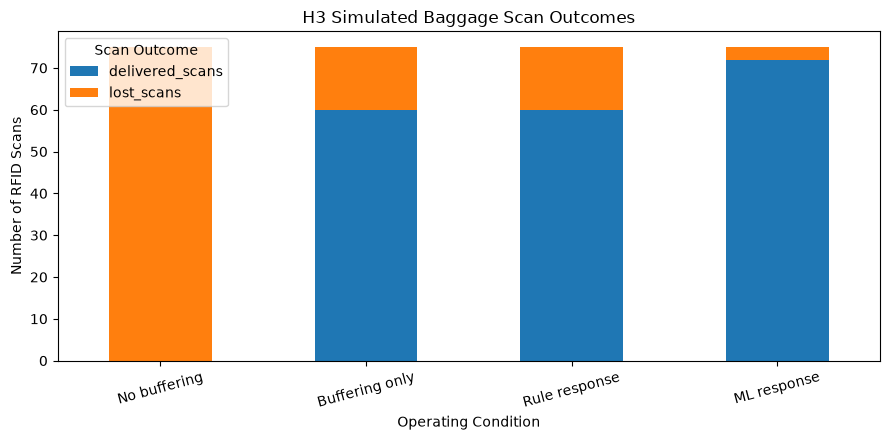

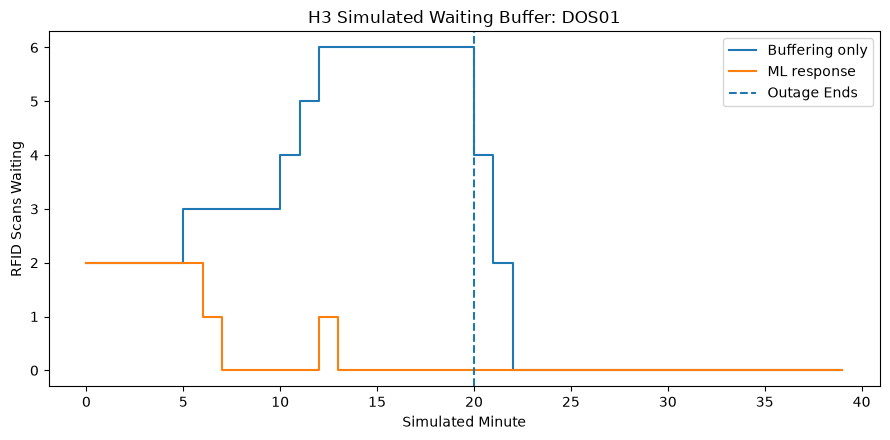


Minute by Minute Operational Demonstration
Disruption: DOS01


,scenario,minute,outage_active,alert_active,new_arrivals,network_capacity,delivered_this_minute,lost_this_minute,waiting_scans
402,Buffering only,0,True,False,2,0,0,0,2
403,Buffering only,1,True,False,0,0,0,0,2
404,Buffering only,2,True,False,0,0,0,0,2
405,Buffering only,3,True,False,0,0,0,0,2
406,Buffering only,4,True,False,0,0,0,0,2
407,Buffering only,5,True,False,1,0,0,0,3
408,Buffering only,6,True,False,0,0,0,0,3
409,Buffering only,7,True,False,0,0,0,0,3
410,Buffering only,8,True,False,0,0,0,0,3
411,Buffering only,9,True,False,0,0,0,0,3



Step 6 complete.


In [6]:
# Step 6: Display the operational simulation and results

# Prepare the comparison data

chart_data = h3_comparison.set_index(
    "scenario"
).loc[scenario_names]

# Create the delivered and lost scan chart

fig, ax = plt.subplots(figsize=(9, 4.5))

chart_data[
    ["delivered_scans", "lost_scans"]
].plot(
    kind="bar",
    stacked=True,
    ax=ax
)

# Label the chart

ax.set_title(
    "H3 Simulated Baggage Scan Outcomes"
)

ax.set_xlabel("Operating Condition")

ax.set_ylabel("Number of RFID Scans")

ax.tick_params(
    axis="x",
    rotation=15
)

ax.legend(
    title="Scan Outcome"
)

fig.tight_layout()

# Save the chart

fig.savefig(
    results_folder / "h3_operational_outcomes.png",
    dpi=160
)

plt.show()


# Review the queue activity for one disruption

example_disruption = "DOS01"

# Create the queue comparison chart

fig, ax = plt.subplots(figsize=(9, 4.5))

# Compare buffering alone with machine learning response

for scenario in [
    "Buffering only",
    "ML response"
]:

    rows = buffer_timeline.loc[
        (
            buffer_timeline["scenario"] == scenario
        )
        & (
            buffer_timeline["disruption_id"]
            == example_disruption
        )
    ]

    ax.step(
        rows["minute"],
        rows["waiting_scans"],
        where="post",
        label=scenario
    )

# Find the end of the disruption

outage_end = int(
    connected_scans.loc[
        connected_scans["disruption_id"]
        == example_disruption,
        "disruption_minutes"
    ].iloc[0]
)

# Mark when communication is restored

ax.axvline(
    outage_end,
    linestyle="--",
    label="Outage Ends"
)

# Label the queue chart

ax.set_title(
    "H3 Simulated Waiting Buffer: DOS01"
)

ax.set_xlabel("Simulated Minute")

ax.set_ylabel("RFID Scans Waiting")

ax.legend()

fig.tight_layout()

# Save the queue chart

fig.savefig(
    results_folder / "h3_operational_queue.png",
    dpi=160
)

plt.show()


# Create a detailed operational activity table

example_replay = buffer_timeline.loc[
    (
        buffer_timeline["disruption_id"]
        == example_disruption
    )
    & (
        buffer_timeline["scenario"].isin([
            "Buffering only",
            "ML response"
        ])
    )
].sort_values(
    ["scenario", "minute"]
)

# Display the activity through the beginning of recovery

print("\nMinute by Minute Operational Demonstration")

print("Disruption:", example_disruption)

display(
    example_replay.loc[
        example_replay["minute"] <= outage_end + 3,
        [
            "scenario",
            "minute",
            "outage_active",
            "alert_active",
            "new_arrivals",
            "network_capacity",
            "delivered_this_minute",
            "lost_this_minute",
            "waiting_scans"
        ]
    ]
)

print("\nStep 6 complete.")

Step 7: Validate the Results and Test the Response Assumptions

The operational simulation is validated to confirm that all 75 affected scans are processed under each operating condition and that each scan receives one recorded outcome.

A sensitivity analysis is performed to examine how the results change when the assumed cybersecurity response timing and protective network capacity are adjusted.

The analysis tests response activation at zero, five, and ten minutes. It also evaluates protective processing capacities of zero, one, and two scans per minute.

A response capacity of zero is used to confirm that an alert alone does not improve operational recovery. The analysis also verifies that removing the machine learning alerts produces the same delivery results as buffering alone.

These tests help determine whether the observed improvements depend on the modeled protective response assumptions.

In [7]:
# Step 7: Validate the results and test response assumptions

# Confirm that each scenario processes the same 75 scans

for scenario in scenario_names:

    rows = scan_outcomes.loc[
        scan_outcomes["scenario"] == scenario
    ]

    assert len(rows) == len(connected_scans)

    assert rows["scan_id"].nunique() == len(
        connected_scans
    )

    assert set(rows["scan_id"]) == set(
        connected_scans["scan_id"]
    )

print("Validation passed: all scans are accounted for.")


# Confirm the traditional rule response matches buffering only

rule_result = h3_comparison.set_index(
    "scenario"
).loc["Rule response"]

assert int(alerts["rule_alert"].sum()) == 0

assert int(rule_result["delivered_scans"]) == int(
    buffering_result["delivered_scans"]
)

assert int(rule_result["lost_scans"]) == int(
    buffering_result["lost_scans"]
)


# Create a list for the sensitivity analysis

sensitivity_rows = []

# Test different response activation times

for response_start in [0, 5, 10]:

    # Test different protective capacities

    for response_rate in [0, 1, 2]:

        # Run the ML response under these settings

        test_outcomes, _ = simulate_scans(
            connected_scans,
            "ML response",
            buffer_size=buffer_capacity,
            recovery_rate=recovery_capacity,
            response_start=response_start,
            response_rate=response_rate
        )

        # Count successfully delivered scans

        delivered = int(
            (
                test_outcomes["status"] == "Delivered"
            ).sum()
        )

        # Count lost scans

        lost = len(test_outcomes) - delivered

        # Calculate the average delivery delay

        average_delay = (
            test_outcomes["delay_minutes"].mean()
        )

        # Save the sensitivity measurements

        sensitivity_rows.append({
            "response_start_minute": response_start,
            "protected_scans_per_minute": response_rate,
            "delivered_scans": delivered,
            "lost_scans": lost,
            "average_delay_minutes": (
                round(average_delay, 2)
                if delivered > 0
                else None
            )
        })

# Create the sensitivity results table

h3_sensitivity = pd.DataFrame(
    sensitivity_rows
)

# Display the results

print("\nH3 Response Sensitivity Analysis:")

display(h3_sensitivity)


# Verify that an alert without protection gives no benefit

no_protection = h3_sensitivity.loc[
    h3_sensitivity["protected_scans_per_minute"] == 0
]

assert (
    no_protection["delivered_scans"]
    == int(buffering_result["delivered_scans"])
).all()

assert (
    no_protection["lost_scans"]
    == int(buffering_result["lost_scans"])
).all()


# Test the simulation without any ML alerts

no_alert_scans = connected_scans.copy()

no_alert_scans["ml_alert"] = 0

# Run the ML response with alerts removed

no_alert_results, _ = simulate_scans(
    no_alert_scans,
    "ML response",
    buffer_size=buffer_capacity,
    recovery_rate=recovery_capacity,
    response_start=response_start_minute,
    response_rate=protected_capacity
)

# Confirm results match buffering alone

assert int(
    (
        no_alert_results["status"] == "Delivered"
    ).sum()
) == int(
    buffering_result["delivered_scans"]
)

print("\nValidation passed.")

print(
    "An alert without protective capacity does not improve recovery."
)

print(
    "Removing the alerts produces the buffering only results."
)

print("\nStep 7 complete.")

Validation passed: all scans are accounted for.

H3 Response Sensitivity Analysis:


,response_start_minute,protected_scans_per_minute,delivered_scans,lost_scans,average_delay_minutes
0,0,0,60,15,14.25
1,0,1,72,3,2.49
2,0,2,72,3,2.39
3,5,0,60,15,14.25
4,5,1,72,3,3.74
5,5,2,72,3,3.38
6,10,0,60,15,14.25
7,10,1,72,3,6.29
8,10,2,72,3,5.39



Validation passed.
An alert without protective capacity does not improve recovery.
Removing the alerts produces the buffering only results.

Step 7 complete.


Step 8: Save the Operational Evidence and Research Settings

The simulation results are saved to the existing H3 results folder. The saved files include the four scenario comparison results, individual scan outcomes, minute by minute queue activity, response sensitivity results, and two charts.

The simulation settings are also recorded to document the assumed network capacity, buffer size, response activation time, and processing conditions.

The original RFID dataset and Notebook 10 cybersecurity detection results remain unchanged.

The saved outputs support repeatability and provide evidence for explaining the operational simulation during the doctoral defense.

In [8]:
# Step 8: Save the operational evidence and research settings

# Load the library

import json

# Confirm the results folder exists

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Save the four scenario comparison results

h3_comparison.to_csv(
    results_folder / "h3_operational_scenario_comparison.csv",
    index=False
)

# Save the individual scan outcomes

scan_outcomes.to_csv(
    results_folder / "h3_operational_scan_outcomes.csv",
    index=False
)

# Save the minute by minute queue activity

buffer_timeline.to_csv(
    results_folder / "h3_operational_queue_timeline.csv",
    index=False
)

# Save the sensitivity analysis results

h3_sensitivity.to_csv(
    results_folder / "h3_operational_sensitivity.csv",
    index=False
)


# Create a function to identify the exact source files

def file_fingerprint(file):

    digest = hashlib.sha256()

    with file.open("rb") as source:

        for chunk in iter(
            lambda: source.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


# Record the experimental assumptions

run_settings = {
    "input_rfid_file": str(
        rfid_file.relative_to(main_folder)
    ),
    "input_detection_file": str(
        alerts_file.relative_to(main_folder)
    ),
    "rfid_sha256": file_fingerprint(rfid_file),
    "detection_sha256": file_fingerprint(alerts_file),
    "affected_scans": int(len(connected_scans)),
    "disruption_groups": int(
        connected_scans["disruption_id"].nunique()
    ),
    "traditional_rule_alerts": int(
        alerts["rule_alert"].sum()
    ),
    "ml_alerts": int(
        alerts["ml_alert"].sum()
    ),
    "buffer_capacity_scans": buffer_capacity,
    "recovery_capacity_scans_per_minute": recovery_capacity,
    "assumed_response_start_minute": response_start_minute,
    "assumed_protected_capacity_scans_per_minute": protected_capacity,
    "arrival_time_model": (
        "Original scan times mapped into the outage duration"
    ),
    "input_warning": (
        "Network alerts were assigned to RFID disruptions "
        "using the Notebook 10 simulation"
    ),
    "interpretation": (
        "Conditional software simulation, "
        "not measured airport performance"
    )
}

# Save the experimental settings

settings_file = (
    results_folder / "h3_operational_run_settings.json"
)

with settings_file.open("w") as output:

    json.dump(
        run_settings,
        output,
        indent=2
    )

# Display the saved results

print("Operational simulation evidence saved.")

print("\nResults folder:", results_folder)

print("\nSaved files:")

saved_files = [
    "h3_operational_scenario_comparison.csv",
    "h3_operational_scan_outcomes.csv",
    "h3_operational_queue_timeline.csv",
    "h3_operational_sensitivity.csv",
    "h3_operational_outcomes.png",
    "h3_operational_queue.png",
    "h3_operational_run_settings.json"
]

for name in saved_files:

    path = results_folder / name

    print(name, ":", path.exists())

print("\nOriginal research datasets remain unchanged.")

print("\nStep 8 complete.")

Operational simulation evidence saved.

Results folder: /workspaces/Aviation-Baggage-Cybersecurity-Research/09_H3_Results

Saved files:
h3_operational_scenario_comparison.csv : True
h3_operational_scan_outcomes.csv : True
h3_operational_queue_timeline.csv : True
h3_operational_sensitivity.csv : True
h3_operational_outcomes.png : True
h3_operational_queue.png : True
h3_operational_run_settings.json : True

Original research datasets remain unchanged.

Step 8 complete.



Step 9: Evaluate False Cybersecurity Alerts During Normal Operations

The operational simulation is extended to examine how false cybersecurity alerts could affect legitimate RFID baggage tracking activity.

A false alert occurs when a cybersecurity detection system identifies normal activity as suspicious. If the alert activates unnecessary protective controls, legitimate baggage scans may experience additional processing delays or delivery problems.

Normal RFID scan records are selected from the prepared research dataset. These records are reviewed separately from the 75 scans affected by simulated DoS disruptions.

The analysis compares normal network processing with a controlled false alert scenario. The purpose is to determine whether an unnecessary protective response could affect baggage tracking availability.

Any reduction in network processing capacity caused by a false alert is treated as a simulation assumption rather than an observed airport system behavior.

In [9]:

# Step 9: Review normal RFID records

# Check how the dataset identifies normal and abnormal scans

print("RFID scan labels:")

print(
    rfid_data["final_label"].value_counts(
        dropna=False
    )
)

# Check which records are associated with DoS disruptions

print("\nDisruption indicators:")

print(
    rfid_data["disruption_window"].value_counts(
        dropna=False
    )
)

# Select records without simulated DoS disruptions

normal_candidates = rfid_data.loc[
    rfid_data["disruption_window"] == 0
].copy()

# Review their security labels

print("\nSecurity labels outside DoS disruptions:")

print(
    normal_candidates["final_label"].value_counts(
        dropna=False
    )
)

print(
    "\nRecords outside DoS disruptions:",
    len(normal_candidates)
)

print("\nStep 9 data review complete.")


RFID scan labels:
final_label
Normal      30225
Abnormal     1350
Name: count, dtype: int64

Disruption indicators:
disruption_window
0    31500
1       75
Name: count, dtype: int64

Security labels outside DoS disruptions:
final_label
Normal      30225
Abnormal     1275
Name: count, dtype: int64

Records outside DoS disruptions: 31500

Step 9 data review complete.


In [10]:

# Step 9: Part 2 - Prepare normal RFID scans

# Select scans labeled Normal with no DoS disruption

normal_scans = rfid_data.loc[
    (rfid_data["final_label"] == "Normal")
    & (rfid_data["disruption_window"] == 0)
].copy()

# Confirm enough normal records are available

assert len(normal_scans) >= 75, \
    "Not enough normal RFID scans were found."

# Select 75 scans using a fixed random seed

normal_sample = normal_scans.sample(
    n=75,
    random_state=42
).copy()

# Sort the selected scans by original timestamp

normal_sample = normal_sample.sort_values(
    ["timestamp", "scan_id"]
).reset_index(drop=True)

# Assign two scans per simulated minute
# These are controlled arrival times, not actual scan times

normal_sample["scenario_arrival_minute"] = (
    normal_sample.index // 2
)

# Verify the sample

assert normal_sample["scan_id"].is_unique

assert (normal_sample["final_label"] == "Normal").all()

assert (normal_sample["disruption_window"] == 0).all()

# Display the results

print("Normal RFID records available:", len(normal_scans))

print("Selected normal scans:", len(normal_sample))

print(
    "Last simulated arrival minute:",
    normal_sample["scenario_arrival_minute"].max()
)

print("\nSample of normal RFID scans:")

display(
    normal_sample[
        [
            "scan_id",
            "bag_id",
            "final_label",
            "scenario_arrival_minute"
        ]
    ].head(10)
)

print("\nStep 9 Part 2 complete.")


Normal RFID records available: 30225
Selected normal scans: 75
Last simulated arrival minute: 37

Sample of normal RFID scans:


,scan_id,bag_id,final_label,scenario_arrival_minute
0,SCAN13379,BAG2130,Normal,0
1,SCAN23358,BAG3725,Normal,0
2,SCAN05653,BAG0899,Normal,1
3,SCAN30125,BAG4806,Normal,1
4,SCAN17634,BAG2811,Normal,2
5,SCAN05400,BAG0859,Normal,2
6,SCAN01561,BAG0248,Normal,3
7,SCAN03780,BAG0601,Normal,3
8,SCAN13170,BAG2097,Normal,4
9,SCAN20121,BAG3208,Normal,4



Step 9 Part 2 complete.



Step 9: Part 3: Simulate False Cybersecurity Alert Response

The 75 normal RFID scans are processed under two operating conditions. The first represents normal network communication with the ability to deliver two scans per minute. The second introduces a simulated false cybersecurity alert that reduces processing capacity to one scan per minute.

The false alert begins at simulated minute five and remains active for ten minutes. Both conditions use a temporary buffer that can hold six scans.

The program records successful deliveries, lost scans, processing delays, and the number of records waiting in the buffer. This allows the operational effects of an unnecessary protective response to be measured.

The false alert is deliberately introduced as an experimental condition. It is not a false prediction generated by the trained machine learning model. The reduced processing capacity and alert duration are also simulation assumptions rather than measured airport network behavior.

In [11]:

# Step 9: Part 3: Simulate a false cybersecurity alert

# Set the normal network conditions

normal_capacity = 2
normal_buffer = 6

# Set the assumed false alert conditions

false_alert_start = 5
false_alert_duration = 10
false_alert_capacity = 1

# Create lists to save results

false_alert_results = []
false_alert_timeline = []

# Compare normal processing with a false alert

for scenario in ["Normal processing", "False alert"]:

    # Create an empty buffer

    waiting = []

    # Allow extra time to finish processing

    last_minute = (
        int(normal_sample["scenario_arrival_minute"].max())
        + len(normal_sample)
        + 10
    )

    # Process each simulated minute

    for minute in range(last_minute + 1):

        # Find scans arriving at this minute

        arrivals = normal_sample.loc[
            normal_sample["scenario_arrival_minute"] == minute
        ]

        # Set the available network capacity

        capacity = normal_capacity

        # Identify whether the false alert is active

        alert_active = (
            scenario == "False alert"
            and false_alert_start <= minute
            < false_alert_start + false_alert_duration
        )

        # Reduce processing capacity during the false alert

        if alert_active:
            capacity = false_alert_capacity

        # Add new scans to the waiting buffer

        for _, scan in arrivals.iterrows():

            if len(waiting) < normal_buffer:

                waiting.append((
                    scan["scan_id"],
                    minute
                ))

            else:

                # Record scans lost when the buffer is full

                false_alert_results.append({
                    "scenario": scenario,
                    "scan_id": scan["scan_id"],
                    "status": "Lost",
                    "delay_minutes": None
                })

        # Deliver scans according to available capacity

        delivered_count = 0

        for _ in range(min(capacity, len(waiting))):

            scan_id, arrival_minute = waiting.pop(0)

            false_alert_results.append({
                "scenario": scenario,
                "scan_id": scan_id,
                "status": "Delivered",
                "delay_minutes": minute - arrival_minute
            })

            delivered_count += 1

        # Record the network behavior

        false_alert_timeline.append({
            "scenario": scenario,
            "minute": minute,
            "alert_active": alert_active,
            "new_arrivals": len(arrivals),
            "network_capacity": capacity,
            "delivered": delivered_count,
            "waiting_scans": len(waiting)
        })

    # Verify the buffer finished processing

    assert len(waiting) == 0, \
        "Some normal scans remain in the buffer."

# Convert results to tables

false_alert_data = pd.DataFrame(false_alert_results)

false_alert_activity = pd.DataFrame(false_alert_timeline)

# Summarize the operating conditions

false_alert_summary = false_alert_data.groupby(
    "scenario"
).agg(
    delivered_scans=(
        "status",
        lambda values: (values == "Delivered").sum()
    ),
    lost_scans=(
        "status",
        lambda values: (values == "Lost").sum()
    ),
    average_delay_minutes=("delay_minutes", "mean")
).reset_index()

# Calculate the delivery percentage

false_alert_summary["delivery_rate_percent"] = (
    false_alert_summary["delivered_scans"]
    / len(normal_sample)
    * 100
).round(2)

# Verify every scan has one outcome in each scenario

for scenario in ["Normal processing", "False alert"]:

    results = false_alert_data.loc[
        false_alert_data["scenario"] == scenario
    ]

    assert len(results) == 75

    assert results["scan_id"].nunique() == 75

    assert set(results["scan_id"]) == set(
        normal_sample["scan_id"]
    )

# Display the results

print("False Alert Operational Comparison:")

display(false_alert_summary)

print("\nFalse Alert Network Activity:")

display(
    false_alert_activity.loc[
        (false_alert_activity["scenario"] == "False alert")
        & (false_alert_activity["minute"] <= 17)
    ]
)

print("\nAll 75 normal scans accounted for.")

print("\nStep 9 Part 3 complete.")


False Alert Operational Comparison:


,scenario,delivered_scans,lost_scans,average_delay_minutes,delivery_rate_percent
0,False alert,69,6,1.913043,92.0
1,Normal processing,75,0,0.000000,100.0



False Alert Network Activity:


,scenario,minute,alert_active,new_arrivals,network_capacity,delivered,waiting_scans
123,False alert,0,False,2,2,2,0
124,False alert,1,False,2,2,2,0
125,False alert,2,False,2,2,2,0
126,False alert,3,False,2,2,2,0
127,False alert,4,False,2,2,2,0
128,False alert,5,True,2,1,1,1
129,False alert,6,True,2,1,1,2
130,False alert,7,True,2,1,1,3
131,False alert,8,True,2,1,1,4
132,False alert,9,True,2,1,1,5



All 75 normal scans accounted for.

Step 9 Part 3 complete.



Step 9: Part 5: Visualize and Save the False Alert Results

The false alert results are presented using two charts. The first compares delivered and lost RFID scans under normal processing and false alert conditions. The second shows how the number of waiting scans changes over time.

The charts provide visual evidence of the operational effects caused by an unnecessary protective response. The results are also saved as CSV files to support further analysis and research documentation.

The false alert represents a controlled experimental condition. The findings describe the behavior of the simulated system and do not establish the actual false positive rate or operational performance of an airport baggage tracking system.


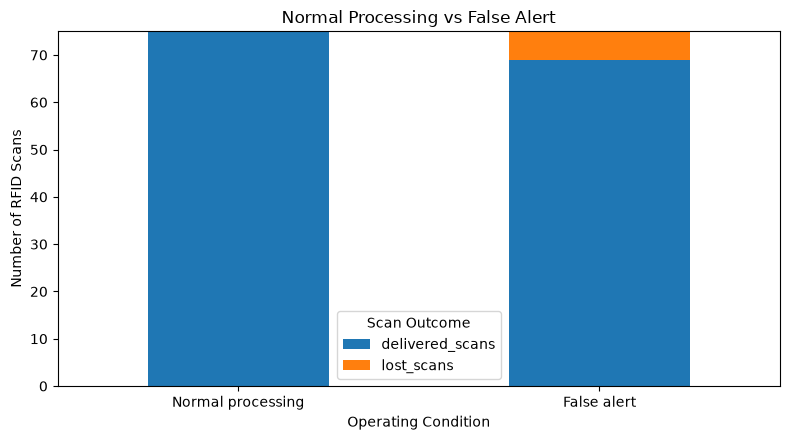

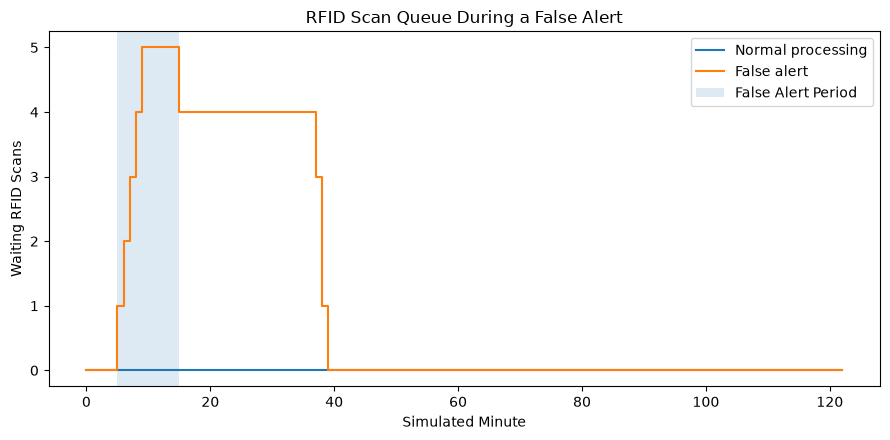

False alert results and charts saved.

Step 9 Part 5 complete.


In [12]:

# Step 9: Part 5: Visualize and save false alert results

# Organize the comparison results

chart_results = false_alert_summary.set_index(
    "scenario"
).loc[
    ["Normal processing", "False alert"]
]

# Create the scan delivery comparison chart

fig, ax = plt.subplots(figsize=(8, 4.5))

chart_results[
    ["delivered_scans", "lost_scans"]
].plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("Normal Processing vs False Alert")

ax.set_xlabel("Operating Condition")

ax.set_ylabel("Number of RFID Scans")

ax.tick_params(axis="x", rotation=0)

ax.legend(title="Scan Outcome")

fig.tight_layout()

# Save the delivery chart

fig.savefig(
    results_folder / "h3_false_alert_outcomes.png",
    dpi=160
)

plt.show()


# Create the waiting queue chart

fig, ax = plt.subplots(figsize=(9, 4.5))

for scenario in ["Normal processing", "False alert"]:

    rows = false_alert_activity.loc[
        false_alert_activity["scenario"] == scenario
    ]

    ax.step(
        rows["minute"],
        rows["waiting_scans"],
        where="post",
        label=scenario
    )

# Mark the duration of the simulated false alert

ax.axvspan(
    false_alert_start,
    false_alert_start + false_alert_duration,
    alpha=0.15,
    label="False Alert Period"
)

ax.set_title("RFID Scan Queue During a False Alert")

ax.set_xlabel("Simulated Minute")

ax.set_ylabel("Waiting RFID Scans")

ax.legend()

fig.tight_layout()

# Save the queue chart

fig.savefig(
    results_folder / "h3_false_alert_queue.png",
    dpi=160
)

plt.show()


# Save the false alert comparison table

false_alert_summary.to_csv(
    results_folder / "h3_false_alert_comparison.csv",
    index=False
)

# Save individual scan results

false_alert_data.to_csv(
    results_folder / "h3_false_alert_scan_outcomes.csv",
    index=False
)

# Save the minute by minute activity

false_alert_activity.to_csv(
    results_folder / "h3_false_alert_timeline.csv",
    index=False
)

# Verify that all scans have an outcome

assert (
    false_alert_summary["delivered_scans"]
    + false_alert_summary["lost_scans"]
    == 75
).all()

print("False alert results and charts saved.")

print("\nStep 9 Part 5 complete.")



Step 9: Part 6: False Alert Validation and Research Interpretation

The false alert simulation examined 75 normal RFID baggage scans under two operating conditions. Normal processing delivered all 75 scans without loss or delay. When a simulated false cybersecurity alert reduced network processing capacity, 69 scans were delivered and six were lost. The delivery rate decreased from 100% to 92%, while the average delay among successfully delivered scans increased to 1.91 minutes.

The false alert began at simulated minute five and remained active for ten minutes. During this period, network processing capacity decreased from two scans per minute to one scan per minute. As new scans continued to arrive, records accumulated in the temporary buffer. Once the buffer reached its maximum capacity, additional scans were lost.

These findings demonstrate that an unnecessary protective response can affect legitimate baggage tracking operations. The results also show why cybersecurity response effectiveness should be evaluated alongside detection performance.

The false alert was introduced as a controlled experimental condition. It was not generated by the trained machine learning detector. Therefore, the results do not establish the detector's actual false positive rate.

The observed losses and delays depend on the selected arrival rate, buffer capacity, alert duration, and processing capacity. They represent the behavior of the simulated system rather than measured performance in an airport environment.

Together with the DoS response experiment, these findings demonstrate both the potential benefits and operational costs of cybersecurity controls in simulated RFID baggage tracking systems.

In [13]:

# Step 9: Part 6: Validate the false alert evidence

# Review the two operating conditions

print("Final False Alert Validation:")

display(false_alert_summary)

# Check that each condition contains 75 scan outcomes

for scenario in ["Normal processing", "False alert"]:

    results = false_alert_data.loc[
        false_alert_data["scenario"] == scenario
    ]

    assert len(results) == 75

    assert results["scan_id"].nunique() == 75

    assert results["status"].isin(
        ["Delivered", "Lost"]
    ).all()

print("\nAll 75 scans accounted for in both conditions.")

# Confirm the research files were saved

saved_files = [
    "h3_false_alert_comparison.csv",
    "h3_false_alert_scan_outcomes.csv",
    "h3_false_alert_timeline.csv",
    "h3_false_alert_outcomes.png",
    "h3_false_alert_queue.png"
]

print("\nSaved research evidence:")

for filename in saved_files:

    file_path = results_folder / filename

    print(filename, ":", file_path.exists())

# Confirm no required file is missing

assert all(
    (results_folder / filename).exists()
    for filename in saved_files
), "One or more research output files are missing."

print("\nStep 9 validation complete.")


Final False Alert Validation:


,scenario,delivered_scans,lost_scans,average_delay_minutes,delivery_rate_percent
0,False alert,69,6,1.913043,92.0
1,Normal processing,75,0,0.000000,100.0



All 75 scans accounted for in both conditions.

Saved research evidence:
h3_false_alert_comparison.csv : True
h3_false_alert_scan_outcomes.csv : True
h3_false_alert_timeline.csv : True
h3_false_alert_outcomes.png : True
h3_false_alert_queue.png : True

Step 9 validation complete.



Step 10: Final Operational Simulation Validation and Defense Evidence

The final validation combines the denial of service response experiment and the false alert experiment to examine the operational effects of cybersecurity controls on RFID baggage tracking availability.

The denial of service experiment compares four operating conditions using 75 affected RFID scans across 10 simulated disruptions. The false alert experiment uses a separate sample of 75 normal RFID scans to evaluate the potential consequences of an unnecessary protective response.

The final analysis verifies scan delivery, record loss, delivery percentages, and processing delays. Each operating condition must account for every scan in its respective sample.

The results provide evidence of the simulated system's behavior under the selected network capacity, buffering, and cybersecurity response assumptions.

The experiments demonstrate modeled operational effects rather than measured performance in an actual airport environment. The detection decisions were obtained from a separate cybersecurity dataset and connected to the RFID simulation through controlled assumptions.

In [14]:

# Step 10: Final operational simulation validation

# Review the DoS simulation results

dos_summary = h3_comparison.copy()

# Identify the experiment

dos_summary["experiment"] = "DoS disruption"

# Review the false alert simulation results

normal_summary = false_alert_summary.copy()

# Identify the separate normal scan experiment

normal_summary["experiment"] = "Normal scan false alert"

# Select the same measurement columns

columns = [
    "experiment",
    "scenario",
    "delivered_scans",
    "lost_scans",
    "delivery_rate_percent",
    "average_delay_minutes"
]

# Combine both experiments

final_summary = pd.concat(
    [
        dos_summary[columns],
        normal_summary[columns]
    ],
    ignore_index=True
)

# Confirm every DoS scenario accounts for 75 scans

assert (
    dos_summary["delivered_scans"]
    + dos_summary["lost_scans"]
    == 75
).all()

# Confirm both normal scan scenarios account for 75 scans

assert (
    normal_summary["delivered_scans"]
    + normal_summary["lost_scans"]
    == 75
).all()

# Verify each scan has one recorded outcome

for scenario in scenario_names:

    rows = scan_outcomes.loc[
        scan_outcomes["scenario"] == scenario
    ]

    assert len(rows) == 75
    assert rows["scan_id"].is_unique

for scenario in ["Normal processing", "False alert"]:

    rows = false_alert_data.loc[
        false_alert_data["scenario"] == scenario
    ]

    assert len(rows) == 75
    assert rows["scan_id"].is_unique

# Confirm the detection decisions remain unchanged

assert int(alerts["rule_alert"].sum()) == 0

assert int(alerts["ml_alert"].sum()) == 8

# Display the complete operational comparison

print("Final H3 Operational Simulation Results:")

display(final_summary)

# Save the final comparison table

final_file = (
    results_folder
    / "h3_final_operational_defense_summary.csv"
)

final_summary.to_csv(
    final_file,
    index=False
)

# Confirm the file was saved

assert final_file.exists()

print("\nValidation passed.")

print("DoS scenarios verified:", len(dos_summary))

print(
    "False alert scenarios verified:",
    len(normal_summary)
)

print("Final research summary saved.")

print("\nStep 10 complete.")


Final H3 Operational Simulation Results:


,experiment,scenario,delivered_scans,lost_scans,delivery_rate_percent,average_delay_minutes
0,DoS disruption,No buffering,0,75,0.0,NaN
1,DoS disruption,Buffering only,60,15,80.0,14.250000
2,DoS disruption,Rule response,60,15,80.0,14.250000
3,DoS disruption,ML response,72,3,96.0,3.740000
4,Normal scan false alert,False alert,69,6,92.0,1.913043
5,Normal scan false alert,Normal processing,75,0,100.0,0.000000



Validation passed.
DoS scenarios verified: 4
False alert scenarios verified: 2
Final research summary saved.

Step 10 complete.



H3 Operational Simulation Findings and Research Interpretation

The operational simulation evaluated 75 RFID baggage scans across 10 simulated denial of service disruptions. Four operating conditions were compared using the same affected scan records and assigned disruption durations.

Without buffering, all 75 scans were lost because the simulated network could not deliver records during the disruptions. A six scan buffer allowed 60 scans to be delivered, while 15 were lost. The average delay among successfully delivered scans was 14.25 minutes.

The traditional rule response produced the same results as buffering alone because none of the 10 disruptions had an assigned traditional rule alert. The machine learning response received alerts for eight disruptions. Under the modeled protective processing conditions, 72 scans were delivered and three were lost. The delivery rate increased from 80% to 96%, while the average delivery delay decreased from 14.25 to 3.74 minutes.

The sensitivity analysis confirmed that detection alerts alone did not improve recovery. Additional processing capacity was necessary for the simulated system to deliver more records. Response activation time also affected the average delivery delay.

A separate false alert experiment evaluated 75 normal RFID scans. Normal processing delivered all 75 scans without loss or delay. When an unnecessary protective response reduced network capacity for ten simulated minutes, 69 scans were delivered and six were lost. The average delay among delivered scans increased to 1.91 minutes.

These findings demonstrate that protective controls can improve simulated baggage tracking availability during disruptions but may also affect legitimate operations when activated unnecessarily.

The cybersecurity detection decisions were obtained from a separate CICIDS2017 experiment and assigned to the RFID disruptions. The modeled protective processing capacity was an experimental assumption rather than an independently measured mitigation capability. The false alert was deliberately introduced and was not generated by the trained detection model.

The results therefore demonstrate conditional operational effects within the software simulation. They do not establish the same performance in an operating airport environment or independently prove that the cybersecurity controls would achieve these improvements in practice.

